# 05 · Distance, networks and accessibility

Lecture 3 · Second part · Slides 24–44.

**Question:** Which pharmacy is closest, and what does “closest” mean?

This follows **04 · Retrieving spatial data and understanding sources**. It uses the same APSS source and `data` directory, but defines its own variables so it can run in a fresh kernel.

Run the cells in order. Each stage contains a learning objective, a Colab AI prompt and a check. Green marks pharmacies, orange marks illustrative origins, blue shows graph relationships or routes, and dashed red shows straight-line alternatives.

**Before starting:** extract the accompanying ZIP beside this notebook. It contains the original APSS CSV and OSM PBF, a derived walking graph and readable provenance. Loading the graph is part of the main exercise; its complete preparation code is in an optional appendix.

[Lecture slides](https://docs.google.com/presentation/d/1O7GzHP081_6ZQ7NMmNPNc_YRGW6WYAKVEWoFSgL7l80)

## Connection with the updated lecture slides

The lecture now includes the original OpenStreetMap teaching slides: commons, contributions and licence (14–18), routing examples (33–35), and isochrones (40).

[Original OSM teaching material](https://docs.google.com/presentation/d/11VyerDOCsohCSefGJd_V2Pi3QBX3v5I2I08iXc7HQZY/edit).

The practical exercises distinguish source observations, proximity relations and permitted movement. A missing OSM object is not evidence that a pharmacy does not exist; a proximity graph is not a walking network.


## APSS source date and metadata

Original source: https://servizi.apss.tn.it/opendata/FARM001.csv

Dataset record: https://dati.trentino.it/it/dataset/farmacie-pat

The server reports **Last-Modified: 30 December 2021** for the downloaded CSV. **29 October 2026 is the retrieval snapshot date, not evidence that the observations were updated in 2026.** The catalogue describes active pharmacies, but the CSV does not provide a validity-end field to reproduce an active-at-date selection.

The catalogue labels the dataset **CC BY 4.0** and its description credits upstream Ministry of Health data under IODL 2.0. Keep both provenance statements and verify their applicability before further redistribution. Attribution: APSS / the publisher shown in the catalogue; upstream source credited in the catalogue. OSM observations and network: © OpenStreetMap contributors, ODbL.

This version uses APSS COD_FARMACIA_OD as the source ID and retains COD_FARMACIA as a separate register code. Numeric P/V agreement does not verify the actual location. The literal column names are preserved in the raw table.


## Reading the variables

| Variable | Meaning |
|---|---|
| pharmacies_raw | Original APSS table, with source columns unchanged |
| pharmacies_study | Mapped observations inside the study rectangle |
| pharmacies / pharmacies_m | Selected scenario, in longitude/latitude / metres |
| origins / origins_m | Explicit teaching origins, in longitude/latitude / metres |
| G_knn / G_radius | Graphs of spatial proximity, not streets |
| G / G_m | Walking graph, in longitude/latitude / metres |
| origin_snap / pharmacy_snap | Assigned graph nodes and point-to-node offsets |
| od_distances | One row for each origin–pharmacy candidate pair |
| comparison | Nearest pharmacy IDs under each distance model |
| accessibility | Counts of distinct services within the chosen threshold |

`_m` denotes metre-based coordinates or distances. `oid` and `pid` are the current origin and pharmacy ID inside loops; `u`, `v`, `key` identify a directed graph edge. New variables are assigned before use.


## Setup

**Slides:** 24–44

**Learning objective:** Use the current documented public APIs in a reproducible environment.

**Colab AI prompt:**

> Install the geospatial, graph and notebook dependencies without PyTorch. Record resolved versions after import.

**Check after execution:** City2Graph is used for proximity graphs. OSMnx and NetworkX implement street-network analysis.

In [ ]:
%pip install -q "geopandas>=1.2,<2" "pandas>=2.2,<4" "osmnx>=2.1,<3" "networkx>=3.4,<4" "city2graph==1.0.1" scipy scikit-learn "matplotlib>=3.10,<4" "requests>=2.32,<3"


## Configuration and source cache

**Slides:** 24–25

**Learning objective:** Keep source reference dates, study extent and retrieval metadata explicit.

**Colab AI prompt:**

> Set up the same source URLs, data directory and manifest as the source-access notebook.

**Check after execution:** The central study window differs from the wider Overpass illustration on slide 22. The APSS retrieval snapshot label is not an official validity date.

In [1]:
# All imports used in later cells are declared here.
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin
import json
import hashlib
import platform
import importlib.metadata
import time
import xml.etree.ElementTree as ET
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display
from shapely.geometry import Point, box

# Directory for source files; generated outputs use separate filenames.
DATA = Path("data")
DATA.mkdir(exist_ok=True)
# Teaching snapshot label, not the dataset reference date or actual download time.
RETRIEVAL_SNAPSHOT_LABEL = pd.Timestamp("2026-10-29")
# Central Trento study window. The slide's Overpass example uses a wider rectangle.
STUDY_BBOX = (11.095, 46.045, 11.145, 46.085)  # west, south, east, north
STUDY_AREA = gpd.GeoSeries([box(*STUDY_BBOX)], crs=4326)
PHARMACY_URL = "https://servizi.apss.tn.it/opendata/FARM001.csv"
PHARMACY_CATALOGUE = "https://dati.trentino.it/it/dataset/farmacie-pat"
USER_AGENT = "unitn-geospatial-lecture3/2026 (educational; mailto:napolitano@fbk.eu)"
# The manifest records request URLs, actual retrieval times and content hashes.
manifest_path = DATA / "source_manifest.json"
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
versions = {
    name: importlib.metadata.version(name)
    for name in ["geopandas", "pandas", "requests"]
}


def cached_get(url, filename, params=None):
    # Define the local path for the file inside the data directory
    path = DATA / filename

    # Show the exact request so the source and parameters remain visible.
    print("Request:", requests.Request("GET", url, params=params).prepare().url)

    # Normalize and prepare the URL with any query parameters to use as a cache key
    prepared_url = requests.Request("GET", url, params=params).prepare().url

    # If the file already exists locally but its registered URL in the manifest differs from the requested one,
    # raise an error to prevent cache collisions or serving incorrect datasets
    if (
        path.exists()
        and filename in manifest
        and manifest[filename].get(
            "url", manifest[filename].get("expected_request_url")
        )
        not in (None, prepared_url)
    ):
        raise ValueError(
            f"Cache query differs for {filename}; choose another filename or review the cache."
        )

    # If the file is not found locally, proceed with downloading it (Cache Miss)
    if not path.exists():
        # Execute the HTTP GET request with a 60-second timeout and a specific User-Agent
        response = requests.get(
            url, params=params, headers={"User-Agent": USER_AGENT}, timeout=60
        )
        response.raise_for_status()  # Raise an exception if the HTTP request failed

        # Save the downloaded binary content to the local file path
        path.write_bytes(response.content)

        # Record download metadata in the manifest (URL, UTC retrieval timestamp, Content-Type, and SHA-256 hash)
        manifest[filename] = {
            "url": prepared_url,
            "retrieved_utc": datetime.now(timezone.utc).isoformat(),
            "content_type": response.headers.get("Content-Type"),
            "last_modified": response.headers.get("Last-Modified"),
            "sha256": hashlib.sha256(response.content).hexdigest(),
        }
        # Update the manifest JSON file on disk
        manifest_path.write_text(json.dumps(manifest, indent=2))

    # If the file exists on disk but has no entry in the manifest (e.g., manually placed files)
    elif filename not in manifest:
        # Register the file in the manifest, compute its SHA-256, and add a provenance disclaimer
        manifest[filename] = {
            "url": None,
            "expected_request_url": prepared_url,
            "retrieved_utc": None,
            "provenance_note": "Local file supplied without retrieval metadata; verify origin.",
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        }
        # Save the updated manifest to disk
        manifest_path.write_text(json.dumps(manifest, indent=2))

    # Validate local file integrity by comparing its current SHA-256 hash with the manifest record
    if hashlib.sha256(path.read_bytes()).hexdigest() != manifest[filename]["sha256"]:
        raise ValueError(f"Cached file changed: {filename}")

    # Return the verified local Path object
    return path


print("Python:", platform.python_version(), "Packages:", versions)
print("Study bbox:", STUDY_BBOX)


Python: 3.12.14 Packages: {'geopandas': '1.2.0', 'pandas': '3.1.0', 'requests': '2.34.2'}
Study bbox: (11.095, 46.045, 11.145, 46.085)


## Pharmacies from APSS FARM001.csv

**Slides:** 3, 6, 23, 25

**Learning objective:** Read the actual APSS schema, preserve source IDs and distinguish observation quality from source validity.

**Colab AI prompt:** Load the original APSS comma-delimited CSV as strings. Preserve COD_FARMACIA_OD and COD_FARMACIA separately. Parse LATITUDINE_P and LONGITUDINE_P and compare them with the decimal-comma V columns. Keep unusable coordinates in a separate audit table. Inspect DATA_INIZIO but do not infer a missing validity-end field or an active-at-date filter. Flag exact shared coordinate pairs without deleting records.

**Check after execution:** Explain each count and every source interpretation. EPSG:4326 is an explicit coordinate interpretation to verify against metadata. No coordinate or address is corrected.


In [2]:
source_csv = cached_get(PHARMACY_URL, "FARM001.csv")
source_hash = hashlib.sha256(source_csv.read_bytes()).hexdigest()
# APSS uses comma-separated quoted fields, unlike the previous ministerial CSV.
pharmacies_raw = pd.read_csv(source_csv, sep=",", dtype=str, encoding="utf-8-sig")
required = {
    "COD_FARMACIA_OD",
    "COD_FARMACIA",
    "FARMACIA",
    "COD_COMUNE",
    "COMUNE",
    "INDIRIZZO",
    "LATITUDINE_P",
    "LONGITUDINE_P",
    "LATITUDINE_V",
    "LONGITUDINE_V",
    "DATA_INIZIO",
    "COD_PROVINCIA",
}
if not required.issubset(pharmacies_raw.columns):
    raise ValueError("APSS schema changed: inspect source columns before proceeding.")
# Rename selected columns for analysis; pharmacies_raw preserves the original schema.
rename = {
    "COD_FARMACIA_OD": "pharmacy_id",
    "COD_FARMACIA": "register_code",
    "FARMACIA": "pharmacy_name",
    "COD_COMUNE": "municipality_code",
    "COMUNE": "municipality",
    "COD_PROVINCIA": "province_code",
    "INDIRIZZO": "address",
    "LATITUDINE_P": "latitude",
    "LONGITUDINE_P": "longitude",
}
records = pharmacies_raw.rename(columns=rename).copy()
records["record_id"] = pharmacies_raw.index
if records["pharmacy_id"].isna().any() or records["pharmacy_id"].duplicated().any():
    raise ValueError(
        "Missing or repeated source IDs: inspect before comparing pharmacies."
    )
# This file does not expose an end-of-validity field. Do not reuse the ministerial active-date filter.
records["start_date_parsed"] = pd.to_datetime(
    records.DATA_INIZIO, format="%Y-%m-%d", errors="coerce"
)
tn_records = records.copy()  # All source rows, not a fabricated active-at-date subset.
for col in ["longitude", "latitude"]:
    tn_records[col] = pd.to_numeric(
        tn_records[col].str.replace(",", ".", regex=False).replace("-", pd.NA),
        errors="coerce",
    )
# Compare the second coordinate representation without overwriting the original.
lat_v = pd.to_numeric(
    tn_records.LATITUDINE_V.str.replace(",", ".", regex=False), errors="coerce"
)
lon_v = pd.to_numeric(
    tn_records.LONGITUDINE_V.str.replace(",", ".", regex=False), errors="coerce"
)
coordinate_columns_agree = np.isclose(
    tn_records.latitude, lat_v, rtol=0, atol=1e-9, equal_nan=True
) & np.isclose(tn_records.longitude, lon_v, rtol=0, atol=1e-9, equal_nan=True)
coordinate_representation_disagreements = tn_records.loc[
    ~coordinate_columns_agree
].copy()
# Numeric ranges detect unusable values, not geographic accuracy.
coord_ok = tn_records.longitude.between(-180, 180) & tn_records.latitude.between(
    -90, 90
)
unmapped_tn = tn_records.loc[~coord_ok].copy()
tn_points = gpd.GeoDataFrame(
    tn_records.loc[coord_ok].copy(),
    geometry=gpd.points_from_xy(
        tn_records.loc[coord_ok, "longitude"], tn_records.loc[coord_ok, "latitude"]
    ),
    crs=4326,
)
# EPSG:4326 is an explicit interpretation of APSS longitude/latitude values.
# Decimal-separator agreement and numeric ranges do not verify positional accuracy.
tn_points["coincident_ids"] = tn_points.groupby(
    ["latitude", "longitude"]
).pharmacy_id.transform("nunique")
# Intersects selects points in or on the study rectangle, not the municipality boundary.
pharmacies_study = tn_points.loc[tn_points.intersects(STUDY_AREA.iloc[0])].copy()
print(
    {
        "apss_source_rows": len(pharmacies_raw),
        "mapped_source_rows": len(tn_points),
        "unmapped_source_rows": len(unmapped_tn),
        "study_points": len(pharmacies_study),
        "P_V_coordinate_disagreements": len(coordinate_representation_disagreements),
    }
)
assert len(tn_records) == len(tn_points) + len(unmapped_tn)
assert source_hash == hashlib.sha256(source_csv.read_bytes()).hexdigest()
display(
    pharmacies_study[
        [
            "record_id",
            "pharmacy_id",
            "register_code",
            "pharmacy_name",
            "address",
            "municipality",
            "coincident_ids",
        ]
    ].head()
)


Request: https://servizi.apss.tn.it/opendata/FARM001.csv
{'apss_source_rows': 181, 'mapped_source_rows': 172, 'unmapped_source_rows': 9, 'study_points': 20, 'P_V_coordinate_disagreements': 0}
    record_id      pharmacy_id  ... municipality  coincident_ids
16         16  FAR042101004178  ...       TRENTO               1
18         18  FAR042101004180  ...       TRENTO               7
24         24  FAR042101004186  ...       TRENTO               1
29         29  FAR042101004191  ...       TRENTO               1
85         85  FAR042101004250  ...       TRENTO               1

[5 rows x 7 columns]


## An explicit analysis scenario

**Slides:** 25, 29, 42

**Learning objective:** Separate source preservation from the decision to use suspect positions.

**Colab AI prompt:**

> Create a scenario switch controlling inclusion of coincident-location flags. Preserve all original records and export the selected and excluded record IDs. Do not geocode or deduplicate automatically.

**Check after execution:** Exclusion is a conservative exercise assumption, not evidence that all shared locations are incorrect.

In [3]:
# Scenario choice: review coincident locations without changing the source file.
# False excludes flagged locations from this comparison; True retains them.
INCLUDE_FLAGGED = False
if INCLUDE_FLAGGED:
    eligible = pd.Series(True, index=pharmacies_study.index)
else:
    eligible = pharmacies_study["coincident_ids"].eq(1)

pharmacies = pharmacies_study.loc[eligible].copy()
scenario_excluded = pharmacies_study.loc[~eligible].copy()
print(
    "Included:", len(pharmacies), "Excluded for this scenario:", len(scenario_excluded)
)

# IDs identify entities; the table index is named separately to avoid join ambiguity.
if pharmacies["pharmacy_id"].isna().any() or not pharmacies["pharmacy_id"].is_unique:
    raise ValueError("Review missing or repeated pharmacy IDs before continuing.")
if len(pharmacies) < 4:
    raise ValueError("The k=3 example needs at least four pharmacy points.")
pharmacies["pharmacy_id"] = pharmacies["pharmacy_id"].astype(str)
pharmacies_m = pharmacies.to_crs(32632)
pharmacies_m = pharmacies_m.set_index("pharmacy_id", drop=False).rename_axis(
    "pharmacy_index"
)

# Keep the excluded records visible: exclusion is an assumption, not a correction.
display(scenario_excluded[["pharmacy_id", "address", "municipality", "coincident_ids"]])
scenario_excluded.drop(columns="geometry").to_csv(
    DATA / "scenario_excluded_pharmacies.csv", index=False
)


Included: 10 Excluded for this scenario: 10
         pharmacy_id                    address municipality  coincident_ids
18   FAR042101004180            PIAZZA PASI, 20       TRENTO               7
86   FAR042101004251           VIA G. MANCI, 42       TRENTO               7
95   FAR042101004261       PIAZZA G. CANTORE, 1       TRENTO               3
98   FAR042101004264          VIA HERRSCHING, 1       TRENTO               7
102  FAR042101004270          VIA FORMIGHETA, 1       TRENTO               3
104  FAR042101004272    LOCALITÀ SOPRAMONTE, 16       TRENTO               7
117  FAR042101016665          LOC. SAN DONÀ, 50       TRENTO               7
121  FAR042101016677         PIAZZALE EUROPA, 8       TRENTO               7
155  FAR042101018181  P.ZZA DELL'ARGENTARIO, 10       TRENTO               7
168  FAR042101018834     VIA ALLE SETTE FONTANE       TRENTO               3


## Illustrative origins

**Slides:** 24–25

**Learning objective:** Avoid mistaking teaching points for a population sample.

**Colab AI prompt:**

> Create four labelled origin points in central Trento with explicit longitude-latitude coordinates and transform them to EPSG:32632.

**Check after execution:** These points are chosen for comparison and do not represent residents or demand.

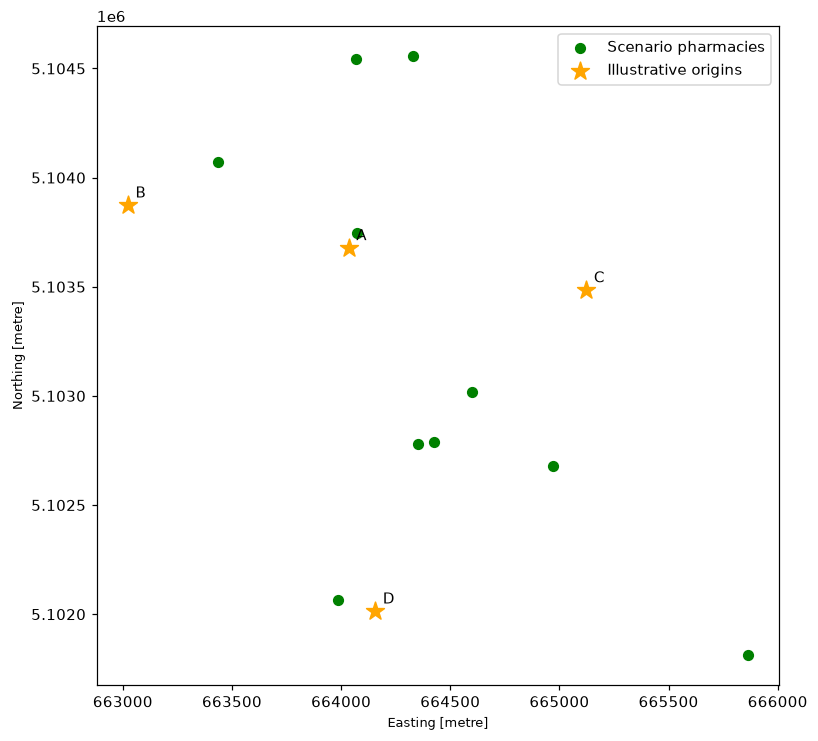

In [4]:
# These four origins are explicit teaching examples, not sampled residents.
origin_rows = [
    {
        "origin_id": "A",
        "description": "Illustrative central origin",
        "longitude": 11.121,
        "latitude": 46.067,
    },
    {
        "origin_id": "B",
        "description": "Illustrative western origin",
        "longitude": 11.108,
        "latitude": 46.069,
    },
    {
        "origin_id": "C",
        "description": "Illustrative eastern origin",
        "longitude": 11.135,
        "latitude": 46.065,
    },
    {
        "origin_id": "D",
        "description": "Illustrative southern origin",
        "longitude": 11.122,
        "latitude": 46.052,
    },
]
origins = gpd.GeoDataFrame(
    origin_rows,
    geometry=gpd.points_from_xy(
        [r["longitude"] for r in origin_rows], [r["latitude"] for r in origin_rows]
    ),
    crs=4326,
)
origins_m = (
    origins.to_crs(32632).set_index("origin_id", drop=False).rename_axis("origin_index")
)
assert origins.intersects(STUDY_AREA.iloc[0]).all()
fig, ax = plt.subplots(figsize=(8, 8))
pharmacies_m.plot(ax=ax, color="green", markersize=40, label="Scenario pharmacies")
origins_m.plot(
    ax=ax, color="orange", marker="*", markersize=150, label="Illustrative origins"
)
for _, row in origins_m.iterrows():
    ax.annotate(
        row.origin_id,
        (row.geometry.x, row.geometry.y),
        xytext=(5, 5),
        textcoords="offset points",
    )
ax.legend()
ax.set_aspect("equal")
plt.show()


## Nearest by planar distance

**Slides:** 24–25

**Learning objective:** Preserve ties and compare metric results, not map impressions.

**Colab AI prompt:**

> Use a nearest spatial join in EPSG:32632 and preserve distinct origin and pharmacy identifiers, all ties and the distance in metres.

**Check after execution:** GeoPandas distance is planar. Do not calculate these metres from degree coordinates.

In [5]:
# A metric nearest join measures straight-line distance and retains equal nearest results.
nearest_air = gpd.sjoin_nearest(
    origins_m[["origin_id", "geometry"]],
    pharmacies_m[["pharmacy_id", "geometry"]],
    how="left",
    distance_col="air_m",
)
display(nearest_air.drop(columns="geometry"))
assert nearest_air.air_m.ge(0).all()


             origin_id   pharmacy_index      pharmacy_id       air_m
origin_index                                                        
A                    A  FAR042101004178  FAR042101004178   79.684614
B                    B  FAR042101016698  FAR042101016698  458.467856
C                    C  FAR042101019298  FAR042101019298  702.390283
D                    D  FAR042101016670  FAR042101016670  177.381348


## Planar and geodesic distance to one destination

**Slides:** 24

**Learning objective:** Compare methods with identical endpoints.

**Colab AI prompt:**

> For one origin and its nearest pharmacy, compare projected planar distance with a WGS84 ellipsoid geodesic calculation. Preserve longitude-latitude ordering.

**Check after execution:** These methods answer a straight-line question; neither computes a walking path.

In [6]:
# Compare identical endpoints: ellipsoid distance versus projected planar distance.
from pyproj import Geod

example_origin = origins.iloc[0]
example_id = nearest_air.loc[
    nearest_air.origin_id.eq(example_origin.origin_id), "pharmacy_id"
].iloc[0]
example_pharmacy = pharmacies.loc[pharmacies.pharmacy_id.eq(example_id)].iloc[0]
_, _, geodesic_m = Geod(ellps="WGS84").inv(
    example_origin.geometry.x,
    example_origin.geometry.y,
    example_pharmacy.geometry.x,
    example_pharmacy.geometry.y,
)
planar_m = origins_m.loc[example_origin.origin_id].geometry.distance(
    pharmacies_m.loc[example_id].geometry
)
print(
    {
        "origin": example_origin.origin_id,
        "pharmacy": example_id,
        "planar_m": planar_m,
        "geodesic_m": geodesic_m,
    }
)


{'origin': 'A', 'pharmacy': 'FAR042101004178', 'planar_m': 79.68461441891712, 'geodesic_m': 79.69012414851683}


## City2Graph proximity models

**Slides:** 26–29

**Learning objective:** Treat each graph edge as an explicit relation between entities.

**Colab AI prompt:**

> Build k=3 Euclidean KNN and 1000-metre radius graphs from the same uniquely indexed point GeoDataFrame. Return node and edge GeoDataFrames and convert them to NetworkX for inspection.

**Check after execution:** A KNN graph within one point layer is undirected by default in this API. Inspect the result instead of assuming every node has degree exactly three.

In [7]:
import city2graph as c2g
import networkx as nx
import osmnx as ox

print(
    {
        pkg: importlib.metadata.version(pkg)
        for pkg in ["city2graph", "osmnx", "networkx"]
    }
)

# First model: link each pharmacy to its three nearest neighbours in metric space.
knn_nodes, knn_edges = c2g.knn_graph(pharmacies_m, k=3, distance_metric="euclidean")
# Second model: link pharmacies separated by at most 1,000 metres in metric space.
radius_nodes, radius_edges = c2g.fixed_radius_graph(
    pharmacies_m, radius=1000, distance_metric="euclidean"
)

# Convert the same relationships to NetworkX to inspect graph structure.
G_knn = c2g.gdf_to_nx(knn_nodes, knn_edges)
G_radius = c2g.gdf_to_nx(radius_nodes, radius_edges)
graph_summary = []
for model_name, graph in [("KNN k=3", G_knn), ("Radius 1000 m", G_radius)]:
    graph_summary.append(
        {
            "model": model_name,
            "nodes": graph.number_of_nodes(),
            "edges": graph.number_of_edges(),
            "directed": graph.is_directed(),
            "isolated": len(list(nx.isolates(graph))),
        }
    )
display(pd.DataFrame(graph_summary))


{'city2graph': '1.0.1', 'osmnx': '2.1.1', 'networkx': '3.7'}
           model  nodes  edges  directed  isolated
0        KNN k=3     10     18     False         0
1  Radius 1000 m     10     14     False         1


## Compare graph choices visually

**Slides:** 29

**Learning objective:** Change one modelling parameter at a time.

**Colab AI prompt:**

> Map both edge sets with identical extent and colours. Show pharmacy points in green and graph relations in blue. Report isolated IDs without calling them inaccessible.

**Check after execution:** Straight relation edges do not describe walkable paths.

Radius-isolated pharmacy IDs: [2]


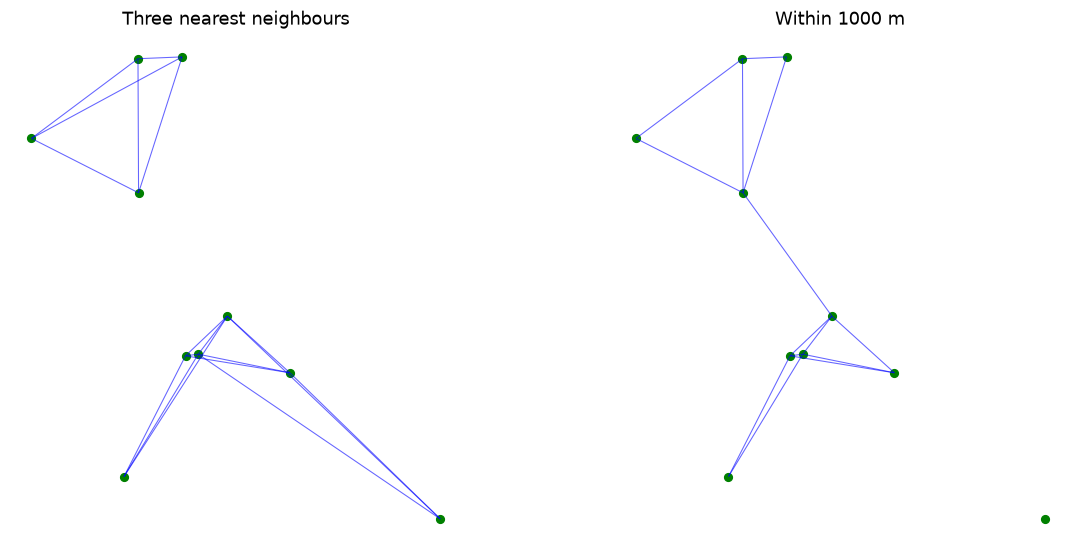

In [8]:
# Use the same extent and colours so graph rules, not map styling, explain differences.
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
for ax, edges, title in [
    (axes[0], knn_edges, "Three nearest neighbours"),
    (axes[1], radius_edges, "Within 1000 m"),
]:
    if not edges.empty:
        edges.plot(ax=ax, color="blue", linewidth=0.7, alpha=0.6)
    pharmacies_m.plot(ax=ax, color="green", markersize=25)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_axis_off()
plt.show()
print("Radius-isolated pharmacy IDs:", list(nx.isolates(G_radius)))


### From proximity relationships to a walking network — slides 30–36

The preceding graphs connect pharmacy locations according to distance rules. Their straight edges do not represent streets.

The next exercise loads **trento_walk_local.graphml**, a derived graph supplied in the ZIP. Its source is the original [Trento OSM municipal PBF](https://osmit-estratti.wmcloud.org/output/pbf/comuni/022205_Trento.osm.pbf), distributed by Wikimedia Italia. The JSON beside it records the source, preparation rules, extent and file hashes. Nothing is encoded in Python.

The preparation keeps selected road and path types, applies a declared access filter and uses `oneway:foot` when available. Otherwise walking is modelled in both directions. It retains disconnected components. The requested extent is the study rectangle plus 1,500 metres; the municipal extract may not cover that whole buffer. Conditional access, turn restrictions, slopes, steps and wheelchair accessibility are not fully modelled.

**Teaching question:** What movement does this graph permit, and what remains unknown? The optional appendix contains the complete preparation code. It is not necessary to teach PBF parsing to explain shortest paths.

Sources: [OSMnx documentation](https://osmnx.readthedocs.io/en/stable/user-reference.html), [Pyosmium documentation](https://docs.osmcode.org/pyosmium/latest/). © OpenStreetMap contributors, [ODbL](https://www.openstreetmap.org/copyright).

## Load and inspect the walking-network source

**Slides:** 30

**Learning objective:** Read a graph with documented provenance before using it to model movement.

**Colab AI prompt:**

> Use DATA from the configuration cell. Read trento_walk_local.metadata.json, print its source and assumptions, verify the hashes of the supplied GraphML and original PBF, and load G with OSMnx. Define G_m by projecting G to EPSG:32632. Do not download or substitute a different network silently.

**Check after execution:** Explain the source, filter, study buffer and limitations. The cached graph is a derived model; the original PBF remains unchanged. If files are missing, extract the ZIP before continuing.

In [9]:
# The graph is a readable GraphML file, accompanied by plain JSON metadata.
graph_path = DATA / "trento_walk_local.graphml"
graph_meta_path = DATA / "trento_walk_local.metadata.json"
pbf_path = DATA / "trento.osm.pbf"
for path in [graph_path, graph_meta_path, pbf_path]:
    if not path.exists():
        raise FileNotFoundError(f"Extract the accompanying ZIP first: missing {path}")

graph_meta = json.loads(graph_meta_path.read_text(encoding="utf-8"))
display(graph_meta)

# Hashes check that we are using the documented files; they do not establish accuracy.
if hashlib.sha256(graph_path.read_bytes()).hexdigest() != graph_meta["sha256"]:
    raise ValueError(
        "The graph differs from its recorded version. Inspect its provenance."
    )
if hashlib.sha256(pbf_path.read_bytes()).hexdigest() != graph_meta["source_sha256"]:
    raise ValueError("The PBF differs from the source recorded for this graph.")

# Verify that this graph was prepared for the configured study rectangle and buffer.
query_polygon = STUDY_AREA.to_crs(32632).buffer(1500).to_crs(4326).iloc[0]
if query_polygon.wkt != graph_meta["query_polygon_wkt"]:
    raise ValueError("Study extent changed: prepare and document a matching graph.")

G = ox.io.load_graphml(graph_path)
G_m = ox.projection.project_graph(G, to_crs="EPSG:32632")
print("Nodes:", G_m.number_of_nodes(), "Edges:", G_m.number_of_edges())
print("Weakly connected components:", nx.number_weakly_connected_components(G_m))


{'source_url': 'https://osmit-estratti.wmcloud.org/output/pbf/comuni/022205_Trento.osm.pbf', 'source_sha256': '2d8996caeec0e70b397c3030d1bf42ba0a8c1dccad96ef344f7418137c081eaa', 'query_polygon_wkt': 'POLYGON ((11.144993968976184 46.03150414703994, 11.095006148280916 46.0315039364703, 11.093106518753553 46.03156850959417, 11.09122511671671 46.031762454810874, 11.089380055481957 46.032083905145534, 11.087589099299747 46.03252976601784, 11.08586949265914 46.03309574496519, 11.08423779453745 46.03377639287898, 11.082709719181791 46.034565156360955, 11.081299984944373 46.035454440700846, 11.080022172619017 46.03643568287441, 11.078888594638453 46.037499433865584, 11.077910176391018 46.03863544952596, 11.077096350802577 46.039832789103286, 11.076454967205342 46.04107992049585, 11.075992215381211 46.042364831224845, 11.075712565524226 46.043675144060366, 11.075618724715977 46.04499823619121, 11.075604712648916 46.08499847288472, 11.07569762392197 46.086321059787835, 11.075976366040209 46.0876

## Inspect graph geometry and costs

**Slides:** 26, 30–32

**Learning objective:** Separate graph identity, geometry and edge length.

**Colab AI prompt:**

> Extract graph node and edge GeoDataFrames, inspect relevant attributes, and verify that length costs are finite and nonnegative.

**Check after execution:** Use the length attribute consistently. A projected line geometry and an accumulated OSMnx length attribute need not be identical.

                               osmid  ...                                           geometry
u          v          key             ...                                                   
9191982    9013746935 0    124889872  ...  LINESTRING (663774.62 5101777.834, 663780.027 ...
           2454602411 0    306341971  ...  LINESTRING (663774.62 5101777.834, 663766.996 ...
           9013746938 0    306341971  ...  LINESTRING (663774.62 5101777.834, 663775.651 ...
9013746935 9191982    0    124889872  ...  LINESTRING (663780.027 5101777.122, 663774.62 ...
           1388563583 0    124889872  ...  LINESTRING (663780.027 5101777.122, 663787.85 ...

[5 rows x 6 columns]


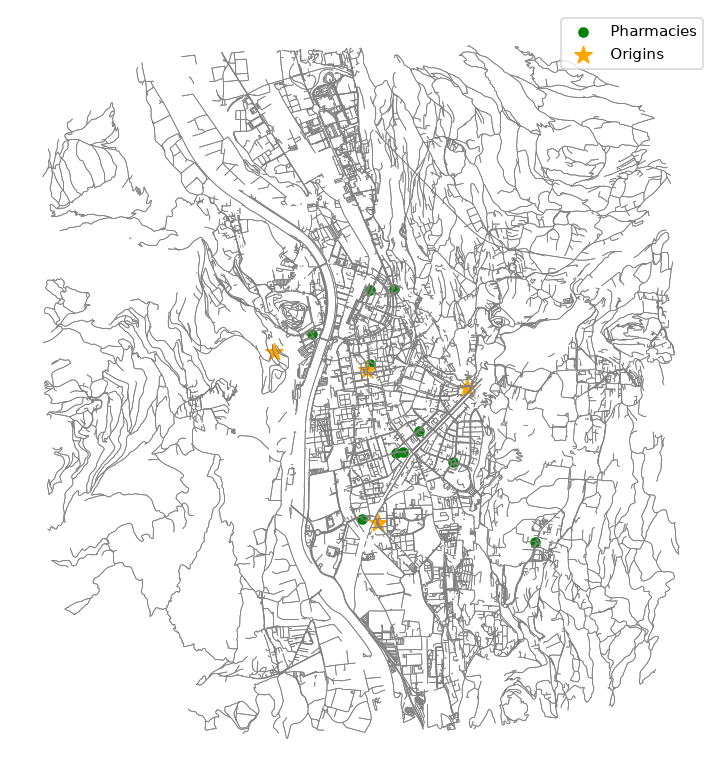

In [10]:
# Each edge has geometry for display and a length attribute used as its routing cost.
nodes_m, edges_m = ox.convert.graph_to_gdfs(G_m)
display(
    edges_m[
        [
            c
            for c in [
                "osmid",
                "highway",
                "name",
                "length",
                "access",
                "foot",
                "geometry",
            ]
            if c in edges_m.columns
        ]
    ].head()
)
assert edges_m.crs.to_epsg() == 32632
assert np.isfinite(edges_m["length"]).all() and edges_m["length"].ge(0).all()
fig, ax = plt.subplots(figsize=(9, 9))
edges_m.plot(ax=ax, color="gray", linewidth=0.5)
pharmacies_m.plot(ax=ax, color="green", markersize=35, label="Pharmacies")
origins_m.plot(ax=ax, color="orange", marker="*", markersize=140, label="Origins")
ax.legend()
ax.set_axis_off()
plt.show()


## Snapping and connection offsets

**Slides:** 31

**Learning objective:** Record the assumptions introduced by nearest-node assignment.

**Colab AI prompt:**

> Snap origin and pharmacy points to the projected graph, preserve source coordinates and report offsets. Flag offsets over 100 metres without automatically changing the source observations.

**Check after execution:** A small offset does not prove a legal entrance or barrier-free connection.

In [11]:
# Assign points to graph nodes and retain offsets; proximity does not prove access.
MAX_OFFSET_M = 100.0
origin_node_ids, origin_offsets = ox.distance.nearest_nodes(
    G_m,
    X=origins_m.geometry.x.to_numpy(),
    Y=origins_m.geometry.y.to_numpy(),
    return_dist=True,
)
pharmacy_node_ids, pharmacy_offsets = ox.distance.nearest_nodes(
    G_m,
    X=pharmacies_m.geometry.x.to_numpy(),
    Y=pharmacies_m.geometry.y.to_numpy(),
    return_dist=True,
)
origin_snap = pd.DataFrame(
    {
        "origin_id": origins_m.origin_id.to_numpy(),
        "node": origin_node_ids,
        "offset_m": origin_offsets,
    }
).set_index("origin_id", drop=False)
pharmacy_snap = pd.DataFrame(
    {
        "pharmacy_id": pharmacies_m.pharmacy_id.to_numpy(),
        "node": pharmacy_node_ids,
        "offset_m": pharmacy_offsets,
    }
).set_index("pharmacy_id", drop=False)
origin_snap["offset_ok"] = origin_snap.offset_m.le(MAX_OFFSET_M)
pharmacy_snap["offset_ok"] = pharmacy_snap.offset_m.le(MAX_OFFSET_M)
display(origin_snap)
display(pharmacy_snap)


          origin_id         node   offset_m  offset_ok
origin_id                                             
A                 A  12884519165   4.991687       True
B                 B   8500537983  39.119437       True
C                 C  13351171027  21.463916       True
D                 D   1422902417  46.199175       True
                     pharmacy_id         node   offset_m  offset_ok
pharmacy_id                                                        
FAR042101004178  FAR042101004178   1125127446   5.381522       True
FAR042101004186  FAR042101004186    264726754  12.644851       True
FAR042101004191  FAR042101004191    428315119   6.635104       True
FAR042101004250  FAR042101004250   2315892543   2.962179       True
FAR042101016627  FAR042101016627    277357721  12.687546       True
FAR042101016670  FAR042101016670    260914931   6.037223       True
FAR042101016698  FAR042101016698  11224710411   7.667530       True
FAR042101018168  FAR042101018168  13287422075  19.354208  

## Origin–pharmacy distances with explicit status

**Slides:** 36–38, 42

**Learning objective:** Keep all candidate pairs, including review and unreachable cases.

**Colab AI prompt:**

> Calculate shortest length distances from each origin node to all candidate pharmacy nodes. Preserve origin and pharmacy IDs, snapping offsets, planar distance, network metres and unreachable status. Report hypothetical connector costs separately.

**Check after execution:** network_m measures node-to-node travel. model_with_connectors_m adds straight connectors whose physical validity still needs review.

In [12]:
# One row per origin–pharmacy pair: no candidate silently disappears.
rows = []
for oid, origin in origin_snap.iterrows():
    # Dijkstra adds edge lengths from this origin to reachable graph nodes.
    if origin.offset_ok:
        lengths = nx.single_source_dijkstra_path_length(
            G_m, origin.node, weight="length"
        )
    else:
        lengths = {}

    for pid, dest in pharmacy_snap.iterrows():
        network_m = np.nan
        if not origin.offset_ok:
            status = "origin_connection_review"
        elif not dest.offset_ok:
            status = "pharmacy_connection_review"
        elif dest.node not in lengths:
            status = "unreachable_in_graph"
        else:
            status = "reachable_in_model"
            network_m = lengths[dest.node]

        # Keep two meanings separate: node-to-node path and hypothetical point connectors.
        connector_m = float(origin.offset_m + dest.offset_m)
        air_m = origins_m.loc[oid].geometry.distance(pharmacies_m.loc[pid].geometry)
        rows.append(
            {
                "origin_id": oid,
                "pharmacy_id": pid,
                "air_m": air_m,
                "network_m": network_m,
                "origin_offset_m": origin.offset_m,
                "pharmacy_offset_m": dest.offset_m,
                "connector_m": connector_m,
                "model_with_connectors_m": network_m + connector_m,
                "status": status,
            }
        )
od_distances = pd.DataFrame(rows)
assert len(od_distances) == len(origins_m) * len(pharmacies_m)
display(od_distances)
print(od_distances["status"].value_counts())


   origin_id  ...                status
0          A  ...  unreachable_in_graph
1          A  ...  unreachable_in_graph
2          A  ...  unreachable_in_graph
3          A  ...  unreachable_in_graph
4          A  ...  unreachable_in_graph
5          A  ...  unreachable_in_graph
6          A  ...  unreachable_in_graph
7          A  ...  unreachable_in_graph
8          A  ...  unreachable_in_graph
9          A  ...  unreachable_in_graph
10         B  ...  unreachable_in_graph
11         B  ...    reachable_in_model
12         B  ...    reachable_in_model
13         B  ...    reachable_in_model
14         B  ...    reachable_in_model
15         B  ...    reachable_in_model
16         B  ...    reachable_in_model
17         B  ...    reachable_in_model
18         B  ...    reachable_in_model
19         B  ...    reachable_in_model
20         C  ...  unreachable_in_graph
21         C  ...    reachable_in_model
22         C  ...    reachable_in_model
23         C  ...    reachable_in_model


## Nearest destinations and ties

**Slides:** 37–38, 42

**Learning objective:** Compare destination identity and preserve non-results.

**Colab AI prompt:**

> For each origin, list all tied nearest pharmacy IDs by air, network-only length and length plus hypothetical connectors. Preserve origins with no reachable candidates.

**Check after execution:** The model with connectors can select a different destination from the network-only model.

In [13]:
# Compare the same candidate set under three definitions of distance.
comparison_rows = []
distance_models = [
    ("air", "air_m"),
    ("network", "network_m"),
    ("with_connectors", "model_with_connectors_m"),
]
for oid in origins_m["origin_id"]:
    pairs = od_distances.loc[od_distances["origin_id"].eq(oid)]
    result = {"origin_id": oid}
    for label, column in distance_models:
        valid = pairs.loc[np.isfinite(pairs[column])]
        if valid.empty:
            # An empty list means no candidate result; it does not mean zero distance.
            result[label + "_ids"] = []
            result[label + "_m"] = np.nan
        else:
            minimum = valid[column].min()
            # Preserve all ties within a tiny numerical tolerance, in metres.
            tied = np.isclose(valid[column], minimum, rtol=0, atol=1e-6)
            result[label + "_ids"] = sorted(valid.loc[tied, "pharmacy_id"].tolist())
            result[label + "_m"] = minimum
    if result["network_ids"]:
        result["same_air_network_destination_set"] = set(result["air_ids"]) == set(
            result["network_ids"]
        )
    else:
        result["same_air_network_destination_set"] = pd.NA
    comparison_rows.append(result)
comparison = pd.DataFrame(comparison_rows)
display(comparison)


  origin_id  ... same_air_network_destination_set
0         A  ...                             <NA>
1         B  ...                             True
2         C  ...                             True
3         D  ...                             True

[4 rows x 8 columns]


## A selected path and an edge-sum check

**Slides:** 36–37

**Learning objective:** Sum only the edges that belong to the selected route.

**Colab AI prompt:**

> Extract one reachable shortest path using the same weight for path selection and route_to_gdf. Check the sum against the OD matrix and map its straight-line alternative.

**Check after execution:** Blue is the network route. Red dashed is the straight line to the same destination. Green marks pharmacies, orange the origin.

{'origin': 'B', 'pharmacy': 'FAR042101016698', 'network_m': 1964.7532492731677, 'source_to_source_air_m': 458.46785561393045}


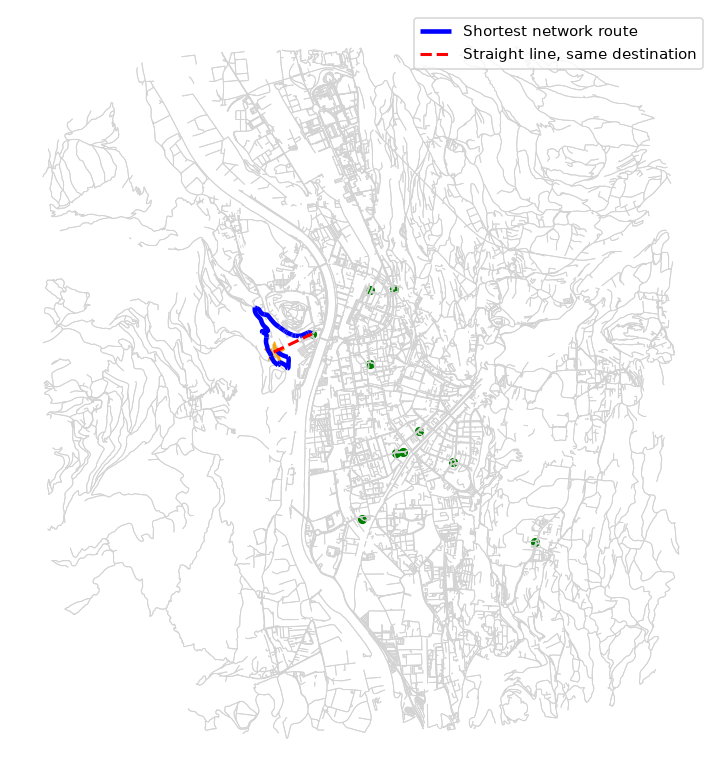

In [14]:
# Choose one reachable pair for illustration; keep all pairs in od_distances.
from shapely.geometry import LineString

reachable_examples = comparison.loc[comparison.network_ids.map(bool)]
if not reachable_examples.empty:
    chosen = reachable_examples.iloc[0]
    oid = chosen.origin_id
    pid = chosen.network_ids[0]
    route = ox.routing.shortest_path(
        G_m,
        origin_snap.loc[oid, "node"],
        pharmacy_snap.loc[pid, "node"],
        weight="length",
    )
    if route is None:
        raise AssertionError("OD and path retrieval disagree.")
    # The graph may have parallel edges. Use the same weight to select and sum route edges.
    if len(route) > 1:
        route_edges = ox.routing.route_to_gdf(G_m, route, weight="length")
        route_length = float(route_edges["length"].sum())
    else:
        # Both points snapped to the same node: node-to-node distance is zero.
        route_edges = edges_m.iloc[0:0].copy()
        route_length = 0.0
    expected = od_distances.loc[
        od_distances.origin_id.eq(oid) & od_distances.pharmacy_id.eq(pid), "network_m"
    ].iloc[0]
    assert np.isclose(route_length, expected)
    fig, ax = plt.subplots(figsize=(9, 9))
    edges_m.plot(ax=ax, color="lightgray", linewidth=0.6)
    if not route_edges.empty:
        route_edges.plot(
            ax=ax, color="blue", linewidth=3, label="Shortest network route"
        )
    gpd.GeoSeries(
        [LineString([origins_m.loc[oid].geometry, pharmacies_m.loc[pid].geometry])],
        crs=32632,
    ).plot(
        ax=ax,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Straight line, same destination",
    )
    pharmacies_m.plot(ax=ax, color="green", markersize=25)
    origins_m.loc[[oid]].plot(ax=ax, color="orange", marker="*", markersize=180)
    ax.set_axis_off()
    ax.legend()
    plt.show()
    print(
        {
            "origin": oid,
            "pharmacy": pid,
            "network_m": route_length,
            "source_to_source_air_m": float(
                od_distances.loc[
                    od_distances.origin_id.eq(oid) & od_distances.pharmacy_id.eq(pid),
                    "air_m",
                ].iloc[0]
            ),
        }
    )
else:
    print("No reachable origin–pharmacy pair. Inspect offsets, components and extent.")


## A declared walking-speed model

**Slides:** 32, 39

**Learning objective:** Distinguish a distance calculation from a time assumption.

**Colab AI prompt:**

> Assign walk_s from edge length and a declared uniform speed of 4 km/h. Do not impute vehicle speed limits.

**Check after execution:** 4 km/h implies 15 minutes per kilometre under this simplified model; no crossings, slopes or waiting times are measured.

In [15]:
# Convert an explicit speed assumption to metres per second; these are not measured times.
WALK_KMH = 4.0
metres_per_second = WALK_KMH * 1000 / 3600
for u, v, key, attr in G_m.edges(keys=True, data=True):
    attr["walk_s"] = attr["length"] / metres_per_second
od_distances["network_minutes_at_4kmh"] = (
    od_distances.network_m / metres_per_second / 60
)
od_distances["model_minutes_with_connectors"] = (
    od_distances.model_with_connectors_m / metres_per_second / 60
)
display(
    od_distances[
        ["origin_id", "pharmacy_id", "network_m", "network_minutes_at_4kmh", "status"]
    ].head()
)


  origin_id  ...                status
0         A  ...  unreachable_in_graph
1         A  ...  unreachable_in_graph
2         A  ...  unreachable_in_graph
3         A  ...  unreachable_in_graph
4         A  ...  unreachable_in_graph

[5 rows x 5 columns]


## Services within a threshold

**Slides:** 39–42

**Learning objective:** Count distinct service IDs while retaining origins with zero or unknown access.

**Colab AI prompt:**

> For each origin count distinct pharmacies within 1000 metres on the network and under a model that also includes straight connector costs. Report review and unreachable cases separately.

**Check after execution:** Counts refer to this candidate set and graph snapshot. A bad origin connection yields unknown, not zero.

In [16]:
DISTANCE_LIMIT_M = 1000.0  # Analytical choice: one kilometre of modelled travel.
access_rows = []
for oid in origins_m["origin_id"]:
    pairs = od_distances.loc[od_distances["origin_id"].eq(oid)]
    ok_origin = bool(origin_snap.loc[oid, "offset_ok"])
    if ok_origin:
        # Count unique service IDs, not markers or graph nodes.
        within_network = pairs["network_m"].le(DISTANCE_LIMIT_M)
        within_connectors = pairs["model_with_connectors_m"].le(DISTANCE_LIMIT_M)
        network_count = pairs.loc[within_network, "pharmacy_id"].nunique()
        connector_count = pairs.loc[within_connectors, "pharmacy_id"].nunique()
    else:
        # An uncertain origin connection makes the count unknown, not zero.
        network_count = pd.NA
        connector_count = pd.NA
    access_rows.append(
        {
            "origin_id": oid,
            "network_only_count": network_count,
            "with_connectors_count": connector_count,
            "unreachable_candidates": int(
                pairs["status"].eq("unreachable_in_graph").sum()
            ),
            "candidate_connections_requiring_review": int(
                pairs["status"].eq("pharmacy_connection_review").sum()
            ),
            "origin_connection_ok": ok_origin,
        }
    )
accessibility = pd.DataFrame(access_rows)
display(accessibility)


  origin_id  ...  origin_connection_ok
0         A  ...                  True
1         B  ...                  True
2         C  ...                  True
3         D  ...                  True

[4 rows x 6 columns]


## Reachable edges and an explicitly approximate hull

**Slides:** 39–41

**Learning objective:** Separate network evidence from a filled-area representation.

**Colab AI prompt:**

> For the first origin, compute nodes within 1000 metres, select full edges whose traversal fits the remaining budget, and compare them with the convex hull of reachable nodes. Label the hull as approximate.

**Check after execution:** Some edges may be only partly traversable. The full-edge subset is conservative; a convex hull can include inaccessible areas.

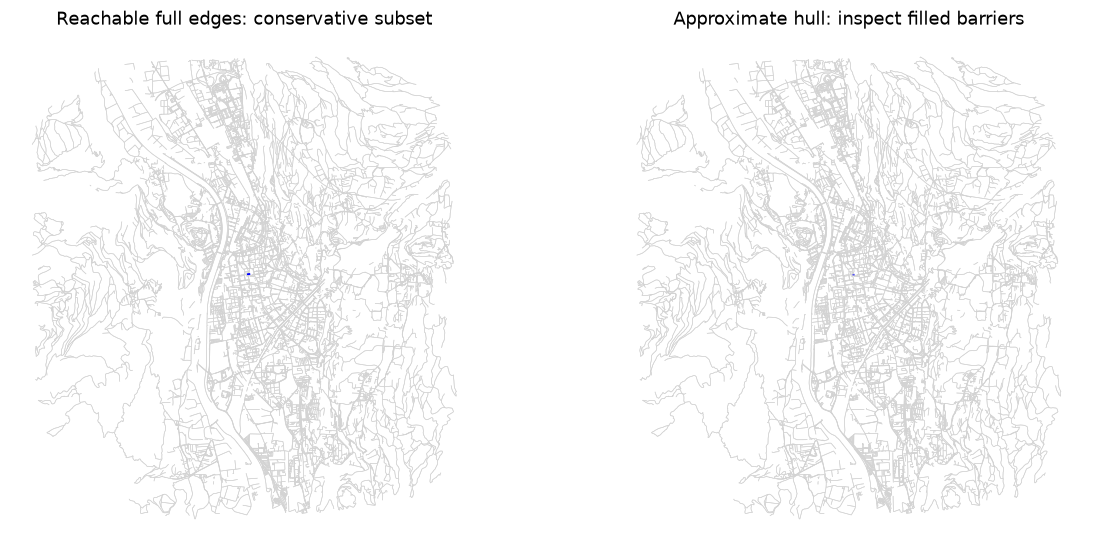

In [17]:
example_oid = origins_m["origin_id"].iloc[0]
if origin_snap.loc[example_oid, "offset_ok"]:
    # Reachability is measured from the snapped node, excluding hypothetical connectors.
    reached = nx.single_source_dijkstra_path_length(
        G_m,
        origin_snap.loc[example_oid, "node"],
        cutoff=DISTANCE_LIMIT_M,
        weight="length",
    )
    reachable_nodes = nodes_m.loc[nodes_m.index.isin(reached)]

    # Include an entire directed edge only if the remaining distance budget allows it.
    full_edge_ids = []
    for u, v, key, attributes in G_m.edges(keys=True, data=True):
        if (
            u in reached
            and reached[u] + attributes["length"] <= DISTANCE_LIMIT_M + 1e-6
        ):
            full_edge_ids.append((u, v, key))
    reachable_edges = edges_m.loc[edges_m.index.isin(full_edge_ids)]

    # A convex hull wraps the reached nodes. It can fill rivers or other barriers.
    approx_hull = reachable_nodes.geometry.union_all().convex_hull
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
    for ax in axes:
        edges_m.plot(ax=ax, color="lightgray", linewidth=0.4)
        ax.set_axis_off()
    if not reachable_edges.empty:
        reachable_edges.plot(ax=axes[0], color="blue", linewidth=2)
    gpd.GeoSeries([approx_hull], crs=32632).plot(
        ax=axes[1],
        facecolor="lightblue",
        edgecolor="blue",
        alpha=0.6,
    )
    axes[0].set_title("Reachable full edges: conservative subset")
    axes[1].set_title("Approximate hull: inspect filled barriers")
    plt.show()
else:
    print("Review the origin connection before interpreting its reachable area.")


## Save results, assumptions and versions

**Slides:** 42–44

**Learning objective:** Make the analysis reproducible and reviewable.

**Colab AI prompt:**

> Export OD distances, tie-preserving nearest-destination comparisons and accessibility counts. Save scenario parameters, package versions and source manifests.

**Check after execution:** The output does not establish opening hours, barrier-free entrances or access for the population.

In [18]:
# Save results, assumptions and excluded records separately from the original source.
od_distances.to_csv(DATA / "origin_pharmacy_distances.csv", index=False)
comparison.assign(
    **{
        c: comparison[c].map(json.dumps)
        for c in ["air_ids", "network_ids", "with_connectors_ids"]
    }
).to_csv(DATA / "nearest_destination_comparison.csv", index=False)
accessibility.to_csv(DATA / "pharmacy_accessibility_counts.csv", index=False)
assumptions = {
    "retrieval_snapshot_label": str(RETRIEVAL_SNAPSHOT_LABEL.date()),
    "include_flagged": INCLUDE_FLAGGED,
    "origins": "Illustrative points, not a population sample",
    "crs": "EPSG:32632",
    "network_mode": "walk",
    "network_query_margin_m": 1500,
    "maximum_snap_offset_m": MAX_OFFSET_M,
    "distance_threshold_m": DISTANCE_LIMIT_M,
    "walking_speed_kmh": WALK_KMH,
    "connector_model": "Straight hypothetical connectors, reported separately; physical access requires review",
    "versions": {
        p: importlib.metadata.version(p)
        for p in ["geopandas", "pandas", "osmnx", "networkx", "city2graph"]
    },
    "opening_hours": "Not included",
    "network_metadata": graph_meta,
}
(DATA / "analysis_assumptions.json").write_text(json.dumps(assumptions, indent=2))
assert source_hash == hashlib.sha256(source_csv.read_bytes()).hexdigest()
print("Saved tables and assumptions in", DATA.resolve())


Saved tables and assumptions in /workspace/scratch/74e21e496575/lecture05/test/data


## AI audit and interpretation — slides 43–44

Ask the AI to review the analysis against the questions below. Check its claims against data and code rather than accepting a fluent explanation.

1. Did every distance use appropriate units and the same endpoints?
2. Did the selected graph represent the intended travel mode?
3. Did snapping create connections across a barrier?
4. Did the route total include only the chosen edges?
5. Did we keep ties, disconnected components and unreachable cases?
6. Did exclusion of flagged coordinates change a result? Rerun with `INCLUDE_FLAGGED=True` only after documenting the comparison scenario.
7. Does a 15-minute estimate imply measured walking time? Which assumptions does it use?
8. What do the data leave unknown about entrances, opening times and individual mobility?

**Submission:** a comparison map, a result table, and a paragraph explaining one modelling choice that changed the answer and one conclusion the data do not support.

### Further resources

[GeoPandas](https://geopandas.org/) · [OSMnx](https://osmnx.readthedocs.io/en/stable/) · [NetworkX](https://networkx.org/) · [City2Graph examples](https://city2graph.net/latest/examples/) · [OSM data licence](https://www.openstreetmap.org/copyright)

City2Graph research citation: Sato, Pietrostefani, Mahabir and Arribas-Bel (2026), *Computers, Environment and Urban Systems*, 130, 102492. https://doi.org/10.1016/j.compenvurbsys.2026.102492

## Optional instructor appendix: prepare the network from its source

This is source preparation, not part of the main student exercise. The code below is the full recipe behind the supplied GraphML. It reads the original municipal PBF, selects ways and referenced nodes, declares walking direction, clips the graph and saves metadata. It does not modify original OSM bytes.

**Learning objective:** Trace the supplied graph to its source and declared processing decisions.

**Colab AI prompt:** Explain the explicit walking filter, node references and direction handling below. Identify assumptions and omitted restrictions. Do not silently replace it with a different transport model.

**Check:** Leave `RUN_NETWORK_PREPARATION=False` for the standard lesson. Preparation needs Pyosmium (`%pip install "osmium>=4,<5"`) and the configuration cells above. Enable it only to prepare a missing graph or inspect the existing one. After changing preparation rules or extent, keep the old graph as a separate scenario and rebuild deliberately. Rerun the main network and analysis cells afterwards.


In [19]:
RUN_NETWORK_PREPARATION = False
if RUN_NETWORK_PREPARATION:
    import osmium, re

    PBF_URL = (
        "https://osmit-estratti.wmcloud.org/output/pbf/comuni/022205_Trento.osm.pbf"
    )
    pbf_path = cached_get(PBF_URL, "trento.osm.pbf")
    query_polygon = STUDY_AREA.to_crs(32632).buffer(1500).to_crs(4326).iloc[0]
    graph_path = DATA / "trento_walk_local.graphml"
    graph_meta_path = DATA / "trento_walk_local.metadata.json"
    query_meta = {
        "source_url": PBF_URL,
        "source_sha256": hashlib.sha256(pbf_path.read_bytes()).hexdigest(),
        "query_polygon_wkt": query_polygon.wkt,
        "walking_filter": "explicit teaching filter v1",
        "foot_direction": "oneway:foot yes/-1, otherwise bidirectional",
    }
    if graph_path.exists():
        if not graph_meta_path.exists():
            raise ValueError("Missing network provenance.")
        graph_meta = json.loads(graph_meta_path.read_text())
        if any(graph_meta.get(k) != v for k, v in query_meta.items()):
            raise ValueError("Network cache provenance differs.")
        if graph_meta["sha256"] != hashlib.sha256(graph_path.read_bytes()).hexdigest():
            raise ValueError("Network cache changed.")
        G = ox.io.load_graphml(graph_path)
    else:
        # First select ways and references, then write referenced nodes before ways.
        # This is a declared teaching model. Source PBF bytes remain unchanged.
        blocked = re.compile(
            "abandoned|bus_guideway|construction|cycleway|motor|no|planned|platform|proposed|raceway|razed|rest_area|services"
        )

        class WalkingWays(osmium.SimpleHandler):
            def __init__(self):
                super().__init__()
                self.ways = []
                self.node_ids = set()

            def way(self, w):
                tags = dict(w.tags)
                if not tags.get("highway") or tags.get("area") == "yes":
                    return
                if blocked.search(tags["highway"]):
                    return
                if (
                    tags.get("access") == "private"
                    or tags.get("service") == "private"
                    or tags.get("foot") == "no"
                ):
                    return
                if any(
                    tags.get(k) == "separate"
                    for k in [
                        "sidewalk",
                        "sidewalk:both",
                        "sidewalk:left",
                        "sidewalk:right",
                    ]
                ):
                    return
                # A general access=no restriction needs an explicit foot exception.
                if tags.get("access") == "no" and tags.get("foot") not in [
                    "yes",
                    "designated",
                    "permissive",
                ]:
                    return
                refs = [nd.ref for nd in w.nodes]
                if len(refs) < 2:
                    return
                tags["source_vehicle_oneway"] = tags.get("oneway", "")
                foot_direction = tags.get("oneway:foot", "no")
                tags["oneway"] = (
                    "yes"
                    if foot_direction in ["yes", "1", "true"]
                    else "-1" if foot_direction == "-1" else "no"
                )
                self.ways.append({"id": w.id, "nodes": refs, "tags": tags})
                self.node_ids.update(refs)

        selected = WalkingWays()
        selected.apply_file(str(pbf_path))
        xml_path = DATA / "trento_walk_derived.osm"

        class WriteNodes(osmium.SimpleHandler):
            def __init__(self, writer):
                super().__init__()
                self.writer = writer
                self.written = set()

            def node(self, node):
                if node.id in selected.node_ids:
                    self.writer.add_node(node)
                    self.written.add(node.id)

        with osmium.SimpleWriter(str(xml_path), overwrite=True) as writer:
            handler = WriteNodes(writer)
            handler.apply_file(str(pbf_path))
            missing = selected.node_ids - handler.written
            if missing:
                raise ValueError(
                    f"Extract lacks {len(missing)} referenced nodes; use a complete source."
                )
            for way in selected.ways:
                writer.add_way(osmium.osm.mutable.Way(**way))
        G_all = ox.graph.graph_from_xml(xml_path, bidirectional=False, retain_all=True)
        G = ox.truncate.truncate_graph_polygon(G_all, query_polygon)
        ox.io.save_graphml(G, graph_path)
        graph_meta = {
            **query_meta,
            "retrieved_utc": manifest["trento.osm.pbf"].get("retrieved_utc"),
            "source": "OpenStreetMap municipal PBF extract distributed by Wikimedia Italia",
            "processed_utc": datetime.now(timezone.utc).isoformat(),
            "osmnx_version": ox.__version__,
            "sha256": hashlib.sha256(graph_path.read_bytes()).hexdigest(),
            "extent_caveat": "The buffered study area can exceed the municipal source coverage.",
            "model_caveat": "Conditional restrictions, steps, slope, wheelchair access and turn relations are not fully modelled.",
        }
        graph_meta_path.write_text(json.dumps(graph_meta, indent=2))
    G_m = ox.projection.project_graph(G, to_crs="EPSG:32632")
    print(
        "Graph:",
        type(G_m),
        "Nodes:",
        G_m.number_of_nodes(),
        "Edges:",
        G_m.number_of_edges(),
    )
    print("Weak components:", nx.number_weakly_connected_components(G_m))
    display(graph_meta)

else:
    print(
        "Optional source preparation skipped; the main exercise loads the supplied graph."
    )


Optional source preparation skipped; the main exercise loads the supplied graph.
